## Pytorch version of batch norm


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [ ]:
# Start with our previous MLP
words = open('names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0
i_to_s = {i:s for s, i in s_to_i.items()}

In [ ]:
block_size = 3

# create the dataset, now we have 228146 datapoints
# implement test and training splits
def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w+'.':
            ix = s_to_i[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

# create the datasets
X_train, Y_train = build_dataset(words[:n1])
X_val, Y_val = build_dataset(words[n1:n2])
X_test, Y_test = build_dataset(words[n2:])

In [ ]:
# Now we create the torch modules to productionise our code
# Note, you would likely not need to write these yourself, but just helps you understand some pytorch internals and the params required

# this will be our standard X x W layer
from typing import Any


class Linear:   
    # initialise simple weights and biases (optional)
    def __init__(self, fan_in, fan_out, bias=True) -> None:
        self.weight = torch.randn((fan_in, fan_out), generator=g) / (fan_in)**0.5 # scale the weights by sqrt(fan_in) to keep std dev around 1
        # for batchnorm the scaling is optional
        self.bias = torch.zeros(fan_out) if bias else None
    
    # compute the pre activations
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    
    # collect weights and biases into one list
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])
    
class BatchNorm:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True # we want to toggle between training mode and inference/eval mode
        # in eval mode, we want to use the running training total as it came out of training, and not touch it at all to avoid leakage from eval sets
        # backprop training params
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # running mean and stddev
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)
        
    def __call__(self, x):
        # forward pass
        if self.training: # get our batch mean and var
            x_mean = x.mean(0, keepdim=True)
            x_var = x.var(0, keepdim=True, unbiased=True)
        else:
            x_mean = self.running_mean
            x_var = self.running_var
        
        x_hat = (x - x_mean) / torch.sqrt(x_var + self.eps) # normalise with mean and std dev
        self.out = self.gamma * x_hat + self.beta # scale with gain and bias

        # the rolling adjustment to the mean and std dev, 
        if self.training:
            with torch.no_grad(): # we dont use backprop to update these as we train, that gets done right here so use no_grad for efficiency
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * x_mean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * x_var

        return self.out
    
    def parameters(self):
        return [self.gamma, self.beta]
    

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []


In [ ]:
# now setup the actual network
vocab_size = 27
embed_dim = 10 # dimensions to embed each letter
n_hidden = 100 # neurons in hidden layer
g = torch.Generator().manual_seed(2147483647)

# embedding matrix - num characters x embedding size 
C = torch.randn((vocab_size, embed_dim), generator=g)


# layers = [
#     # input layer has number of characters x embedding dimension for each character
#     Linear((embed_dim * block_size), n_hidden), Tanh(), 

#     # hidden layers all of same size and with tanh activation
#     Linear(n_hidden, n_hidden), Tanh(),
#     Linear(n_hidden, n_hidden), Tanh(),
#     Linear(n_hidden, n_hidden), Tanh(),
#     Linear(n_hidden, n_hidden), Tanh(),

#     # output layer with vocab size to show probs for each letter
#     Linear(n_hidden, vocab_size)
# ]

# now lets throw in batch norm, generally goes straight after our linear layer but not mandatory
layers = [
    Linear((embed_dim * block_size), n_hidden), BatchNorm(n_hidden), Tanh(), 
    Linear(n_hidden, n_hidden), BatchNorm(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), BatchNorm(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), BatchNorm(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), BatchNorm(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size), BatchNorm(vocab_size)
]

with torch.no_grad():
    # layers[-1].weight *= 0.1 # suppress the final weights to smooth out the softmax into a uniform distribution
    layers[-1].gamma *= 0.1 # for the batchnorm example, we want to tune the gamma since those are the params that are closest to the softmax layer
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3 # for all other weights, initialise using the kaiming gain for tanh (optional for batchnorm)

# get full parameters list
parameters = [C] + [p for layer in layers for p in layer.parameters()]

for p in parameters:
    p.requires_grad = True

In [ ]:
# training loop - as seen before

max_steps = 200000
batch_size = 32
ud = []

for i in range(max_steps):

    # batching
    ix = torch.randint(0, X_train.shape[0], (batch_size, ), generator=g)
    Xb, Yb = X_train[ix], Y_train[ix]

    # set up embed
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)

    # forward pass
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # tell pytorch to hold onto the gradient for non-leaf i.e. intermediate or math created tensors

    for p in parameters:
        p.grad = None
    loss.backward()

    # gradient descent
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # keep track of the update ratio for every parameter
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    
    if i >= 1000:
        break


### Notes on network initialisation (with BatchNorm)

Batchnorm makes the training significantly more robust - we don't need to finely tune our gain, and in some cases we actually don't even need to scale our weights at all and can leave them as gaussian. The diagnostic plots all look good, just need to keep an eye on the update ratio one and tune the learning rate to keep the update ratios close to the 1e-3. 

### Notes on network initialisation (without BatchNorm)

This section will look at some important diagnostic plots when training neural networks, and the importance of careful initialisation, especially if not using batch normalisation. The plots will be produced after the first iteration out of 200k.

these plots include:
- tanh activations for each layer
- gradient for each layer tanh activation
- gradient for each parameter
- gradient to data ratio for each parameter


This first set of graphs is what good looks like without batch norm, using the Kaiming intialised weights (5/3 * 1/sqrt(fan in)) - we will see the importance of this 5/3 for tanh later

**Tanh activations:**

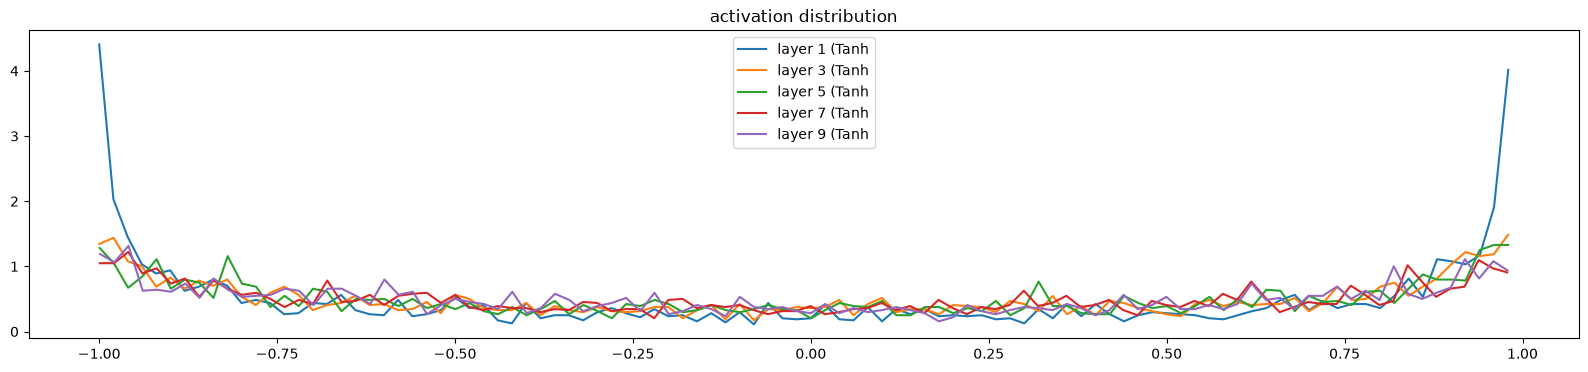

Notice that other than the first layer, all of the layers have a fairly even distribution between 0 and 1. Recall we do not want our tanh activations to be heavily distributed around -1, 1 since the 1-tan^2 gradient wipes the gradient for that entire chain to 0

**Activation Gradients**:

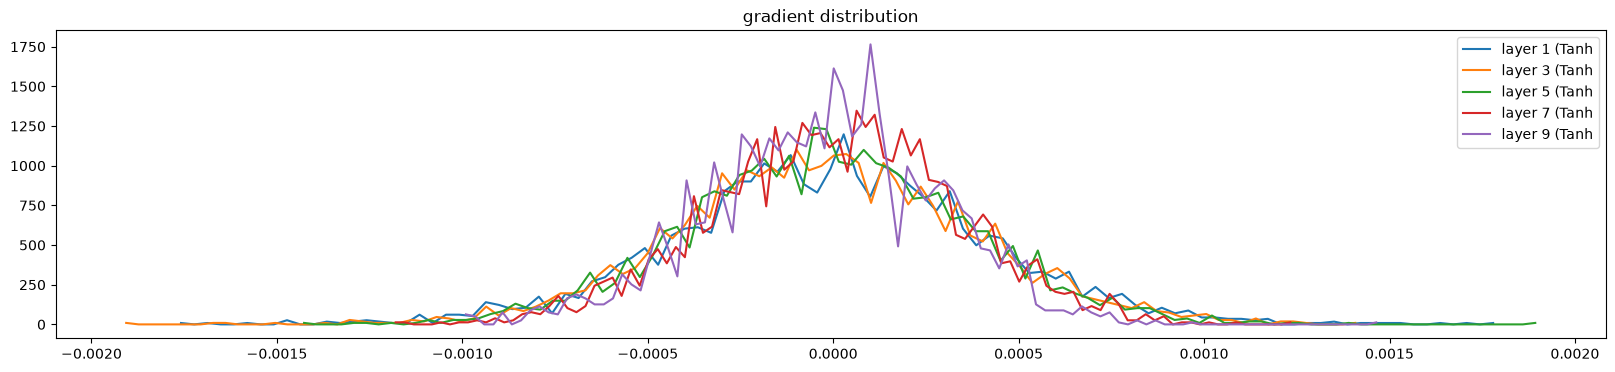

Notice that all of the gradients look the same and look normal


**Parameter Weights:**

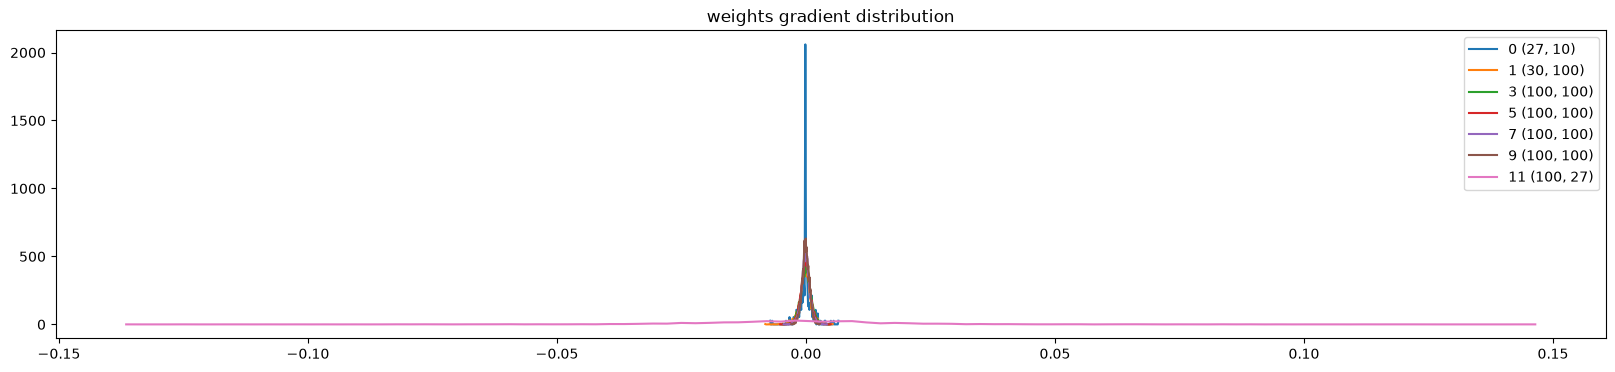

Even with the proper initialisation, our weights look very off (note the blue is the embedding matrix), for example, the pink output layer is very diffuse. This slowly improves as the model trains. However if you look at the param to grad ratio, the last layer is almost 10 times higher, so therefore trains 10 times faster

**Param value to Grad ratios:**

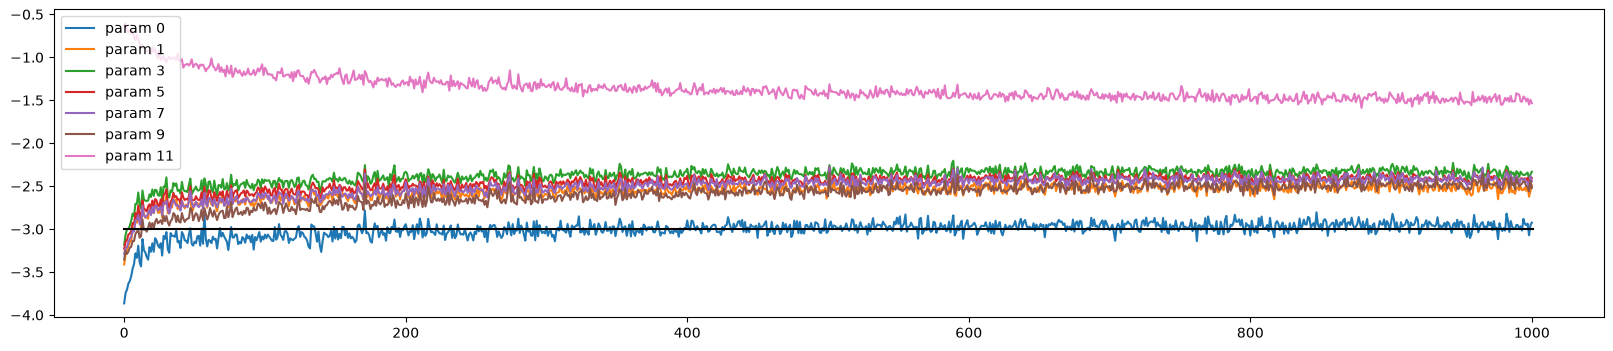

This supports the above claim that the last layer is training too fast. We generally want them around 1e-3, as most of them are except for the pink. This is basically how big of a step is the parameter value taking at each gradient descent iteration with respect to its own value. This is because we artificially reduced the size of the weights in the last layer to remove confidence from the softmax prediction, but now it means that the gradients and the nudges are high with respect the the param size. This is also generally related to your learning rate - if you reduce it too much, your graphs will sit underneath the 1e-3 target line, meaning your model is training too slowly

### Bad initialisation

Now lets look at examples where we dont initialise properly:

Consider a case where we don't set the gain to 5/3, but leave it as 1 or less:

**Tanh activations:**

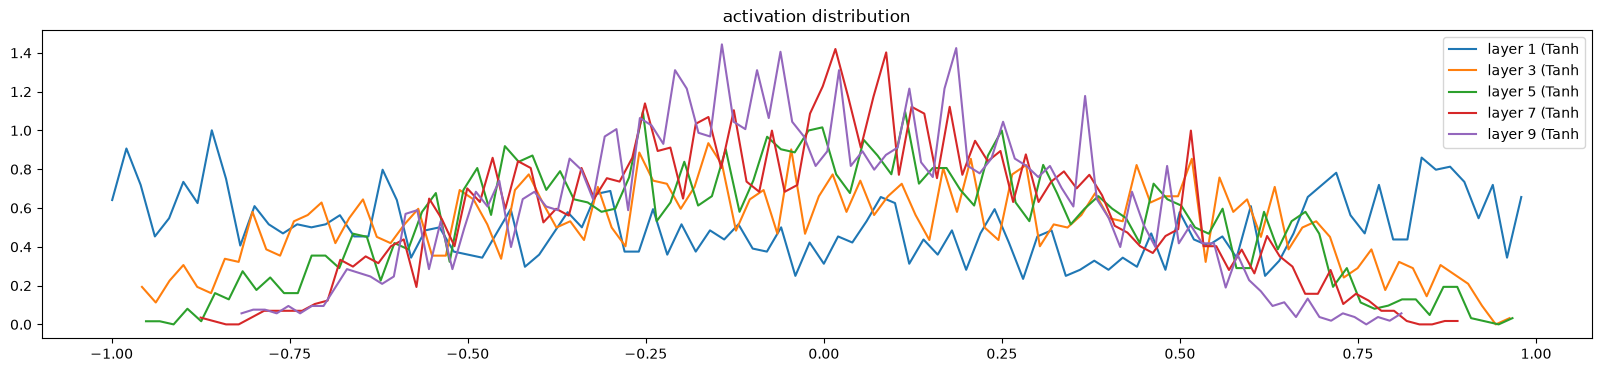

Notice here the first layer is good and evenly distributed, but since tanh is a squeezing function, it starts to squeeze the values toward zero which happens fairly quickly if they don't have that gain applied

**Activation Gradients:**

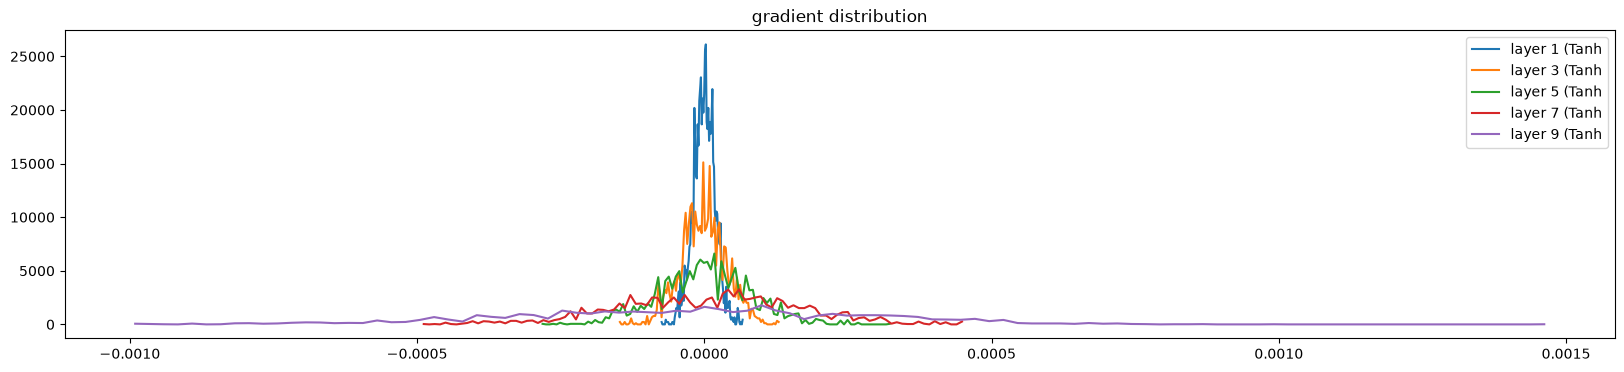

The gradients start to flatten out and all converge to a uniform spread

Now consider the case where we set the gain too high, such as 3:

**Tanh activations:**

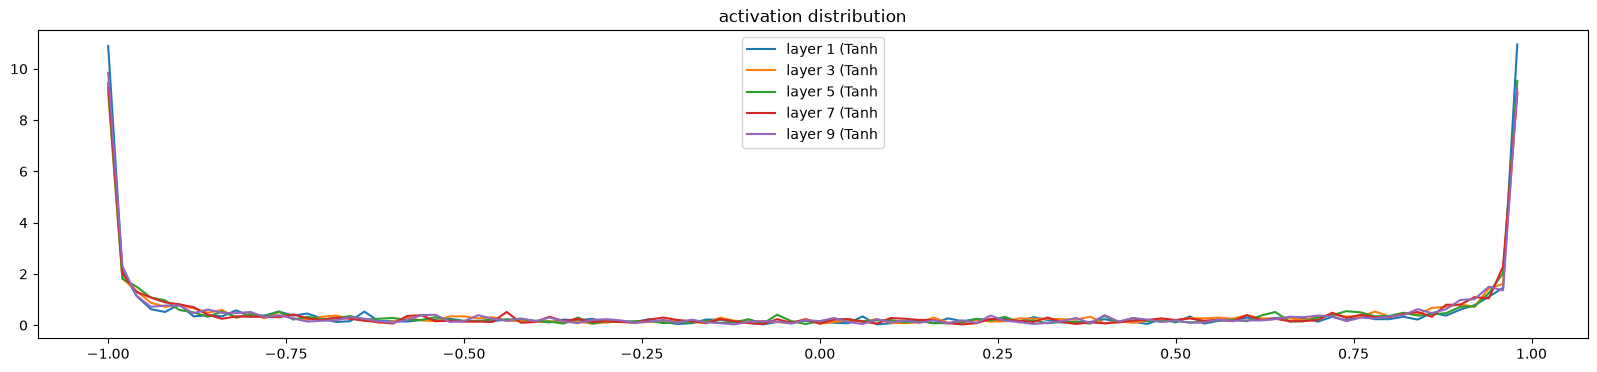

Since the weights are too high, we end up with extreme pre-activations, so tanh will squeeze them to 1, -1. Notice the very high concentration in the tails i.e. saturation for all of the layers. Many gradients will end up dropping out

**Activation Gradients:**

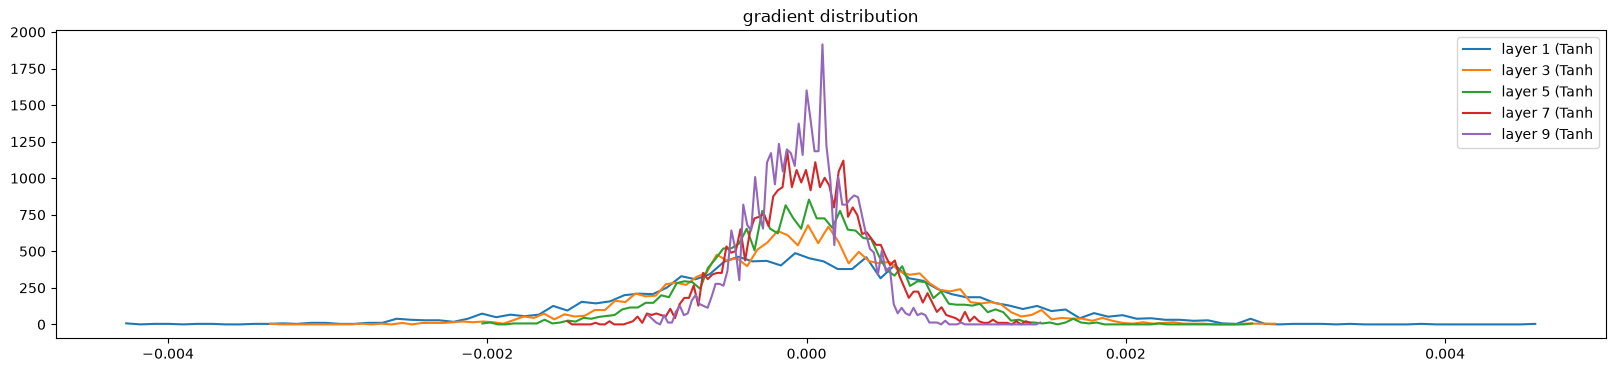

Same as initialising too low, going too high causes the opposite problem of the gradients all starting evenly spread and then start to converge to 0

In [ ]:
# plot the tanh activations for each layer
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

In [ ]:
# plot the gradients for each layer
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

In [ ]:
# plot weights for each layer
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

In [ ]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);